# 01 - EDA: Smart Student Study Planner
Goal: load the data, inspect its structure, build a data dictionary, check data quality.

In [1]:
import pandas as pd

df = pd.read_csv("../data/student-mat.csv", sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
df.shape

(395, 33)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [4]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [5]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
zero_g3 = df[df["G3"] == 0]
print("Rows with G3 = 0:", len(zero_g3))
print("Percentage:", round(len(zero_g3) / len(df) * 100, 1), "%")

Rows with G3 = 0: 38
Percentage: 9.6 %


In [8]:
# Do the zero-grade students look different?
df.assign(is_zero=df["G3"] == 0).groupby("is_zero")[["absences", "failures", "studytime"]].mean()

,absences,failures,studytime
is_zero,,,
False,6.316527,0.271709,2.042017
True,0.000000,0.921053,1.973684


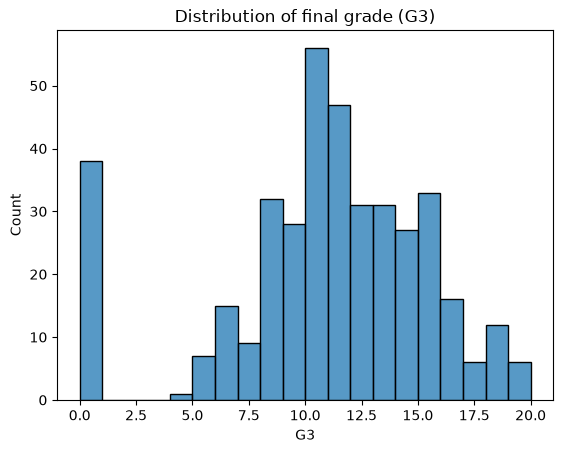

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df["G3"], bins=20)
plt.title("Distribution of final grade (G3)")
plt.xlabel("G3")
plt.show()

In [10]:
df[["G1", "G2", "G3"]].dtypes

G1    int64
G2    int64
G3    int64
dtype: object

| Column | Type | Meaning | Known at planning time? |
|---|---|---|---|
| school | binary | School (GP or MS) | Yes |
| sex | binary | Student's sex | Yes |
| age | numeric | Age (15 to 22) | Yes |
| address | binary | Urban or rural home | Yes |
| famsize | binary | Family size (up to 3, or more than 3) | Yes |
| Pstatus | binary | Parents living together or apart | Yes |
| Medu | ordinal | Mother's education (0 to 4) | Yes |
| Fedu | ordinal | Father's education (0 to 4) | Yes |
| Mjob | categorical | Mother's job | Yes |
| Fjob | categorical | Father's job | Yes |
| reason | categorical | Reason for choosing the school | Yes |
| guardian | categorical | Main guardian | Yes |
| traveltime | ordinal | Home-to-school travel time (1 to 4) | Yes |
| studytime | ordinal | Weekly study time (1 to 4) | Yes |
| failures | numeric | Number of past class failures | Yes |
| schoolsup | binary | Extra educational support from school | Yes |
| famsup | binary | Family educational support | Yes |
| paid | binary | Extra paid classes in the subject | Yes |
| activities | binary | Extracurricular activities | Yes |
| nursery | binary | Attended nursery school | Yes |
| higher | binary | Wants higher education | Yes |
| internet | binary | Internet access at home | Yes |
| romantic | binary | In a romantic relationship | Yes |
| famrel | ordinal | Family relationship quality (1 to 5) | Yes |
| freetime | ordinal | Free time after school (1 to 5) | Yes |
| goout | ordinal | Going out with friends (1 to 5) | Yes |
| Dalc | ordinal | Weekday alcohol use (1 to 5) | Yes |
| Walc | ordinal | Weekend alcohol use (1 to 5) | Yes |
| health | ordinal | Current health status (1 to 5) | Yes |
| absences | numeric | Number of school absences | Judgement call |
| G1 | numeric | First period grade (0 to 20) | No (excluded) |
| G2 | numeric | Second period grade (0 to 20) | No (excluded) |
| G3 | numeric | Final grade (0 to 20) | Target |

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

ordinal_cols = ["Medu", "Fedu", "traveltime", "studytime", "failures",
                "famrel", "freetime", "goout", "Dalc", "Walc", "health"]
cat_cols = ["school", "sex", "address", "famsize", "Pstatus", "Mjob", "Fjob",
            "reason", "guardian", "schoolsup", "famsup", "paid",
            "activities", "nursery", "higher", "internet", "romantic"]

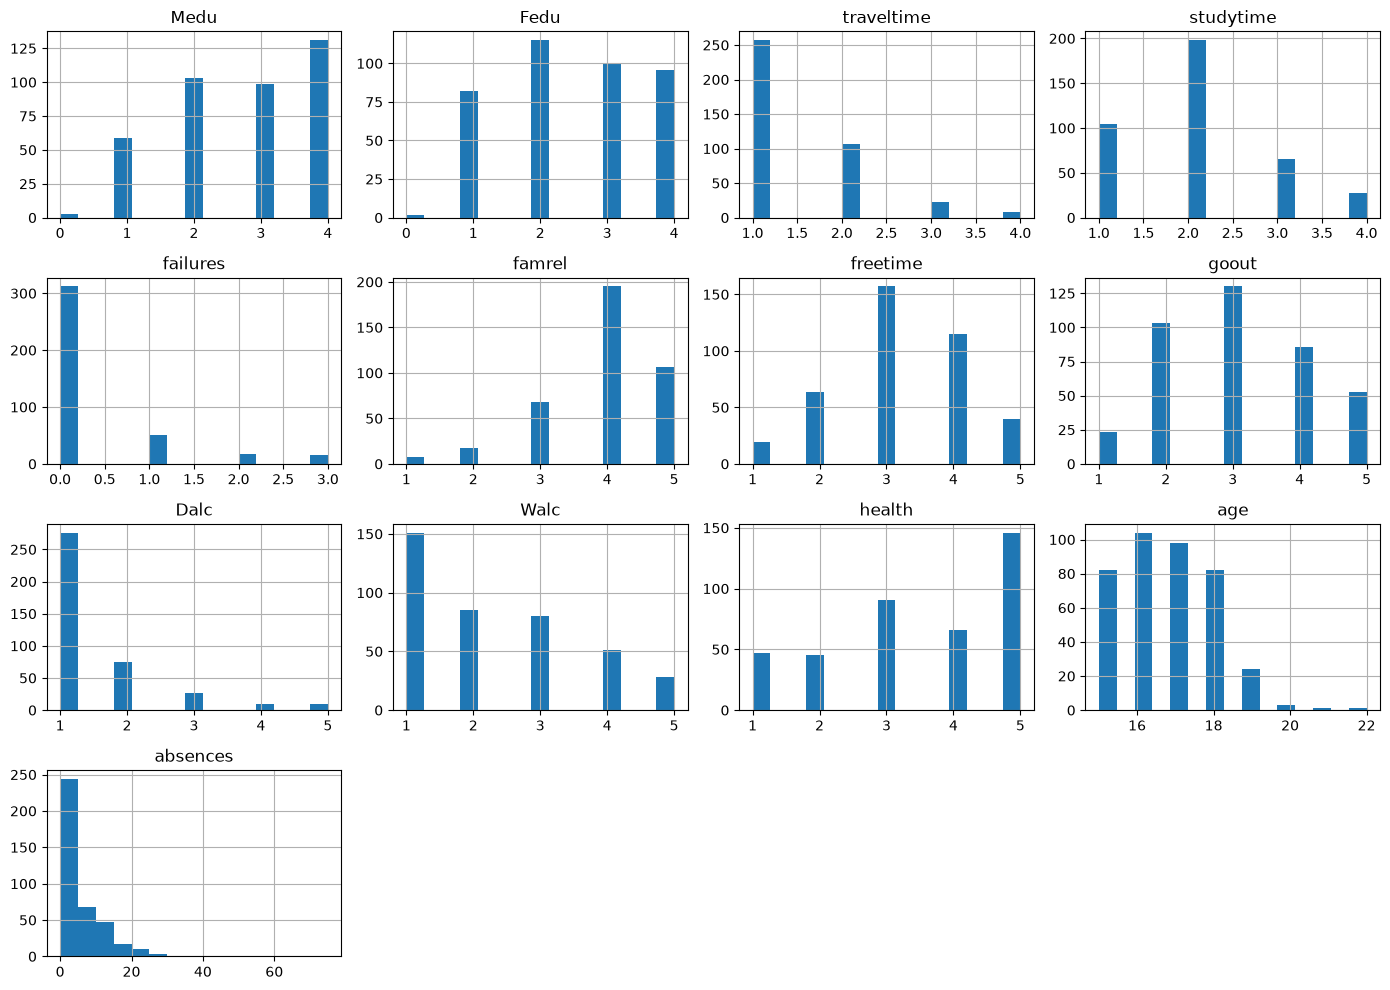

In [5]:
df[ordinal_cols + ["age", "absences"]].hist(figsize=(14, 10), bins=15)
plt.tight_layout()
plt.show()

In [6]:
for col in ordinal_cols:
    print(col)
    print(df.groupby(col)["G3"].agg(["mean", "count"]).round(2))
    print()

Medu
       mean  count
Medu              
0     13.00      3
1      8.68     59
2      9.73    103
3     10.30     99
4     11.76    131

Fedu
       mean  count
Fedu              
0     13.00      2
1      9.16     82
2     10.26    115
3     10.66    100
4     11.36     96

traveltime
             mean  count
traveltime              
1           10.78    257
2            9.91    107
3            9.26     23
4            8.75      8

studytime
            mean  count
studytime              
1          10.05    105
2          10.17    198
3          11.40     65
4          11.26     27

failures
           mean  count
failures              
0         11.25    312
1          8.12     50
2          6.24     17
3          5.69     16

famrel
         mean  count
famrel              
1       10.62      8
2        9.89     18
3       10.04     68
4       10.36    195
5       10.83    106

freetime
           mean  count
freetime              
1          9.84     19
2         11.56     64
3

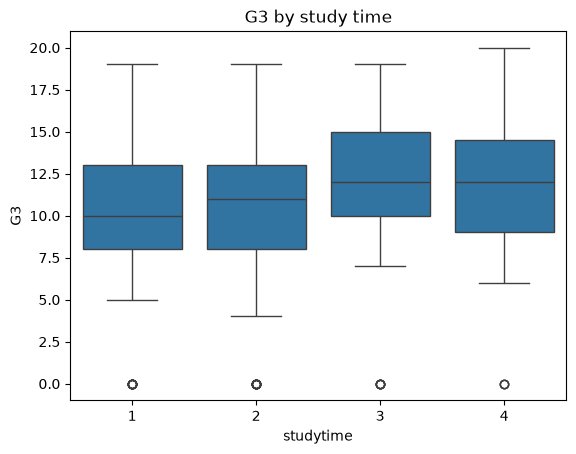

In [9]:
sns.boxplot(x="studytime", y="G3", data=df)
plt.title("G3 by study time")
plt.show()

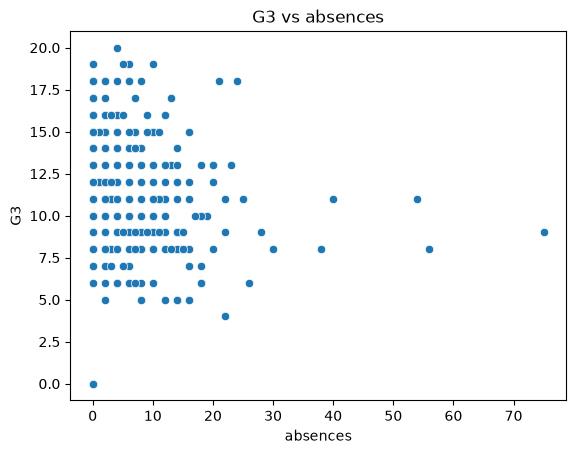

In [10]:
sns.scatterplot(x="absences", y="G3", data=df)
plt.title("G3 vs absences")
plt.show()

In [11]:
df["absences"].describe()

count    395.000000
mean       5.708861
std        8.003096
min        0.000000
25%        0.000000
50%        4.000000
75%        8.000000
max       75.000000
Name: absences, dtype: float64

In [12]:
   df[df["G3"] == 0]["absences"].describe()

count    38.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: absences, dtype: float64

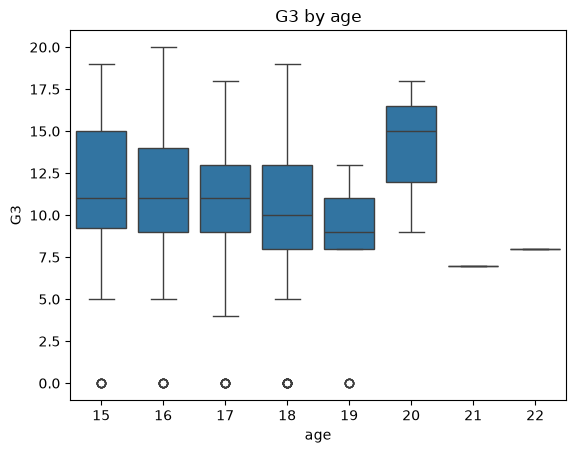

In [13]:
sns.boxplot(x="age", y="G3", data=df)
plt.title("G3 by age")
plt.show()

In [14]:
df.groupby("age")["G3"].agg(["mean", "count"]).round(2)

,mean,count
age,,
15,11.26,82
16,11.03,104
17,10.28,98
18,9.55,82
19,8.21,24
20,14.00,3
21,7.00,1
22,8.00,1


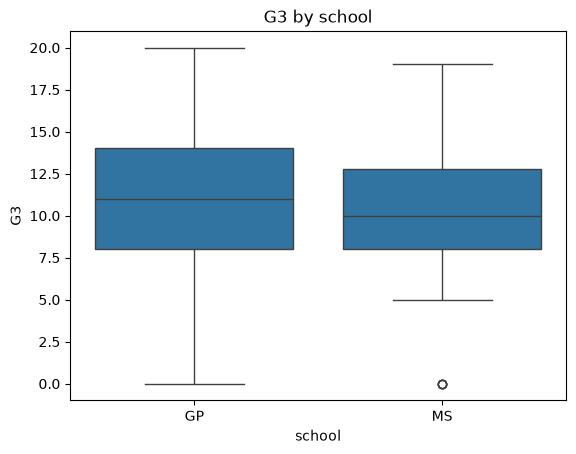

         mean  count
school              
GP      10.49    349
MS       9.85     46



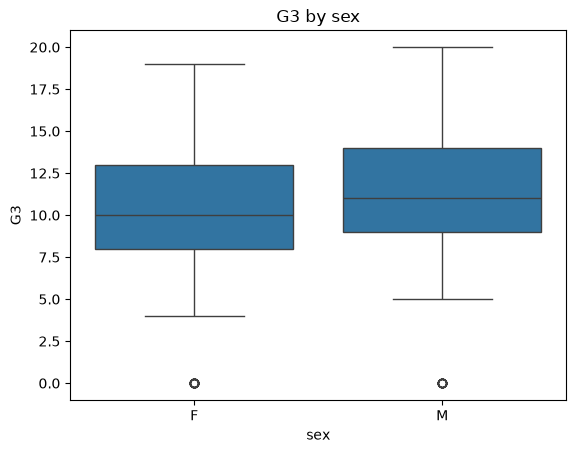

      mean  count
sex              
F     9.97    208
M    10.91    187



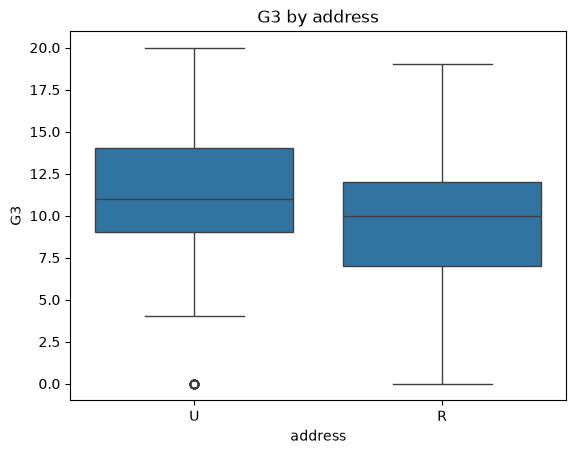

          mean  count
address              
R         9.51     88
U        10.67    307



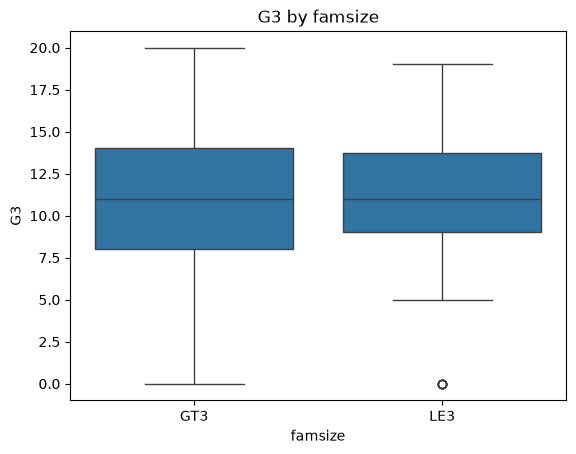

          mean  count
famsize              
GT3      10.18    281
LE3      11.00    114



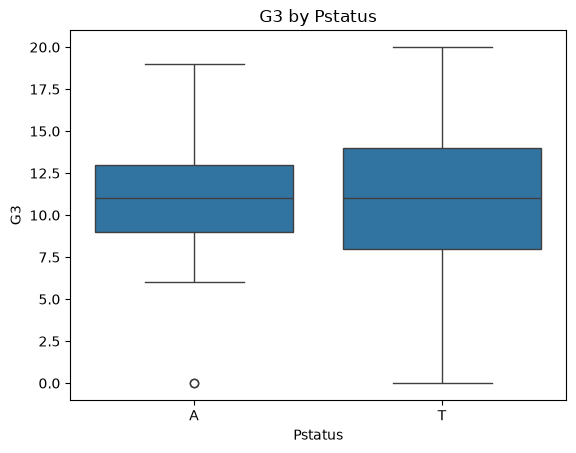

          mean  count
Pstatus              
A        11.20     41
T        10.32    354



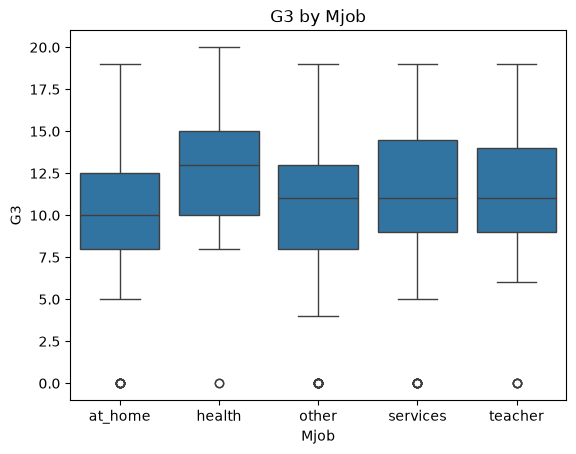

           mean  count
Mjob                  
at_home    9.15     59
health    12.15     34
other      9.82    141
services  11.02    103
teacher   11.05     58



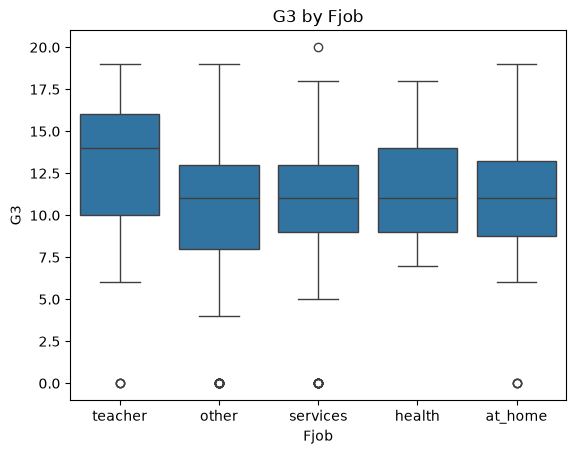

           mean  count
Fjob                  
at_home   10.15     20
health    11.61     18
other     10.19    217
services  10.30    111
teacher   11.97     29



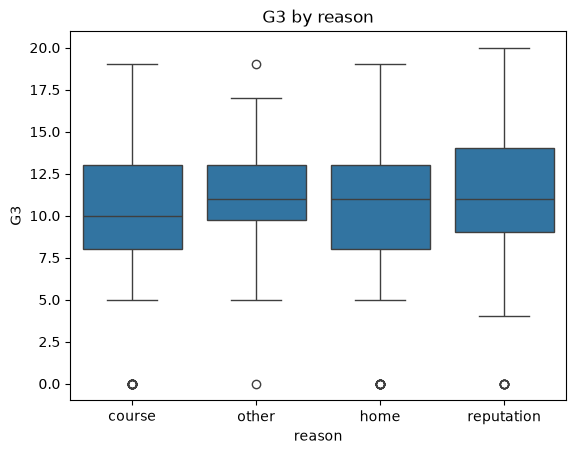

             mean  count
reason                  
course       9.82    145
home        10.26    109
other       11.17     36
reputation  11.14    105



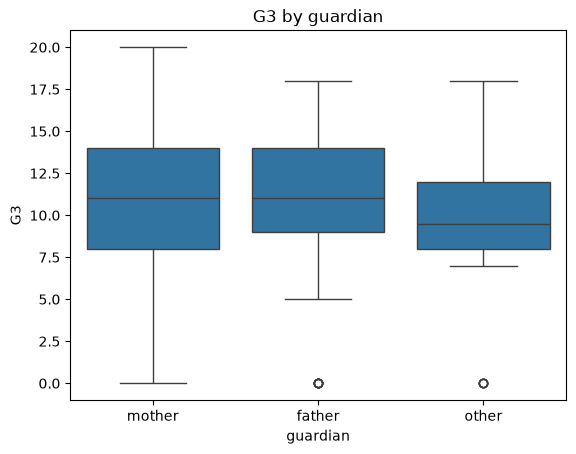

           mean  count
guardian              
father    10.69     90
mother    10.48    273
other      9.06     32



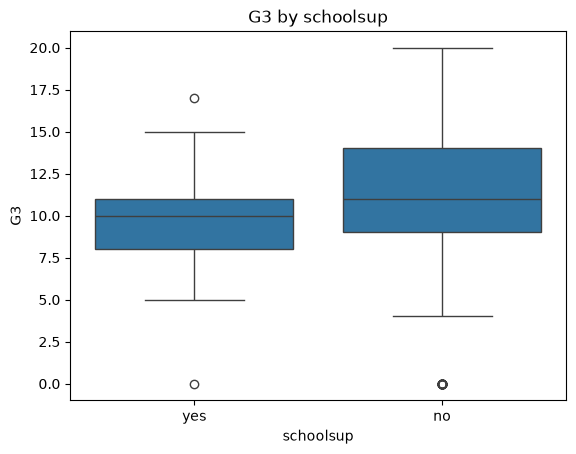

            mean  count
schoolsup              
no         10.56    344
yes         9.43     51



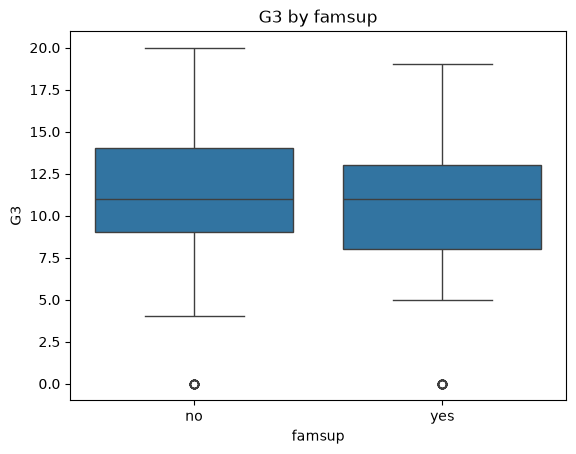

         mean  count
famsup              
no      10.64    153
yes     10.27    242



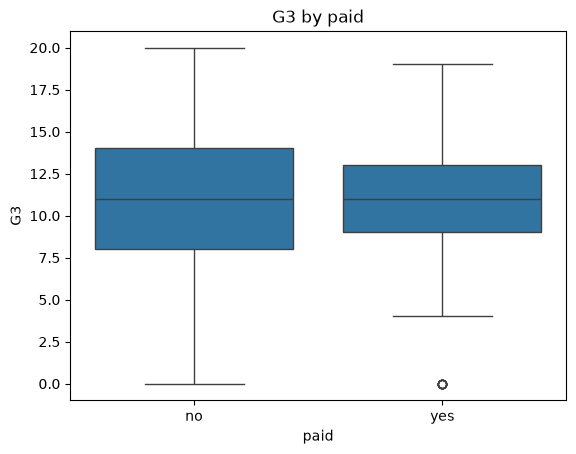

       mean  count
paid              
no     9.99    214
yes   10.92    181



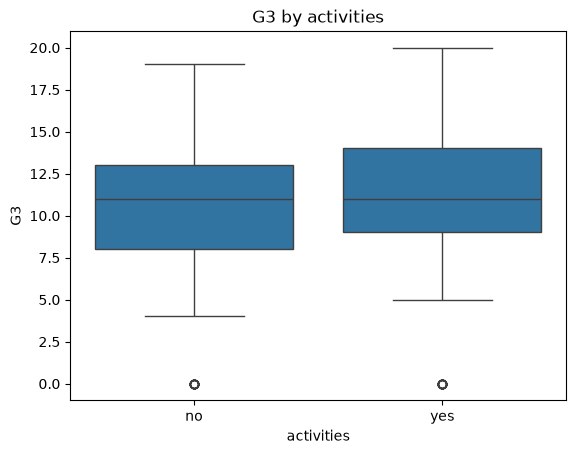

             mean  count
activities              
no          10.34    194
yes         10.49    201



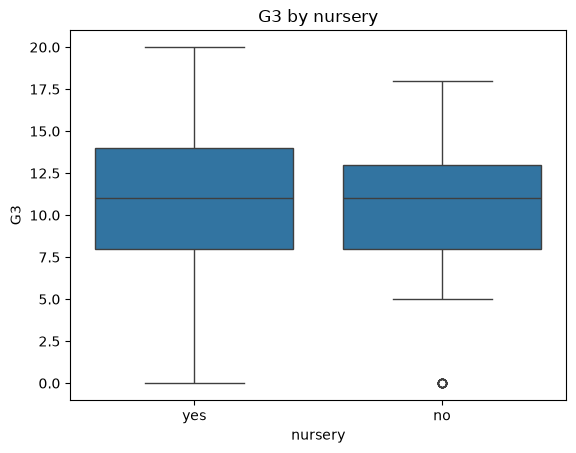

          mean  count
nursery              
no        9.95     81
yes      10.54    314



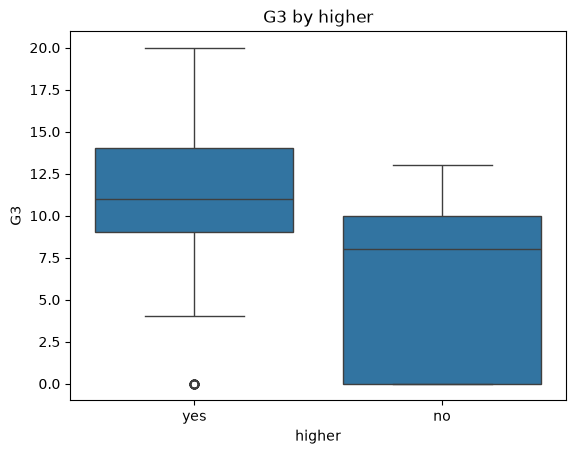

         mean  count
higher              
no       6.80     20
yes     10.61    375



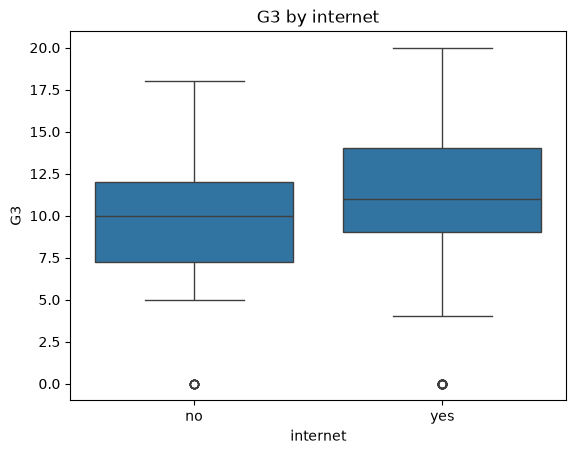

           mean  count
internet              
no         9.41     66
yes       10.62    329



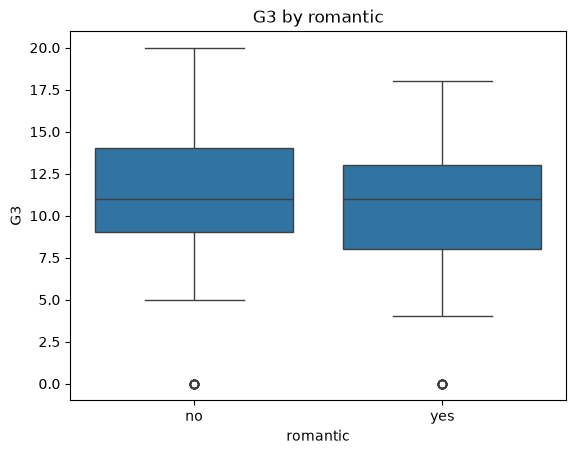

           mean  count
romantic              
no        10.84    263
yes        9.58    132



<Figure size 640x480 with 0 Axes>

In [17]:
for col in cat_cols:
    sns.boxplot(x=col, y="G3", data=df)
    plt.title(f"G3 by {col}")
    plt.show()
    plt.tight_layout()
    print(df.groupby(col)["G3"].agg(["mean", "count"]).round(2))
    print()

In [18]:
df_clean = df[df["G3"] > 0]
for col in ["failures", "studytime", "higher", "schoolsup", "absences"]:
    print(col)
    print(df_clean.groupby(col)["G3"].agg(["mean", "count"]).round(2).head(10))
    print()

failures
           mean  count
failures              
0         11.94    294
1         10.15     40
2          8.83     12
3          8.27     11

studytime
            mean  count
studytime              
1          11.47     92
2          11.07    182
3          12.56     59
4          12.67     24

higher
         mean  count
higher              
no       9.71     14
yes     11.60    343

schoolsup
            mean  count
schoolsup              
no         11.83    307
yes         9.62     50

absences
           mean  count
absences              
0         12.61     77
1         13.00      3
2         11.91     65
3         11.50      8
4         11.28     53
5         11.60      5
6         11.77     31
7         11.86      7
8         10.59     22
9         13.33      3



In [19]:
df_clean = df[df["G3"] > 0]

for col in ["failures", "studytime", "higher", "schoolsup"]:
    with_zeros = df.groupby(col)["G3"].agg(["mean", "count"]).round(2).add_suffix("_all")
    no_zeros = df_clean.groupby(col)["G3"].agg(["mean", "count"]).round(2).add_suffix("_nozero")
    print(col)
    print(with_zeros.join(no_zeros))
    print()

failures
          mean_all  count_all  mean_nozero  count_nozero
failures                                                
0            11.25        312        11.94           294
1             8.12         50        10.15            40
2             6.24         17         8.83            12
3             5.69         16         8.27            11

studytime
           mean_all  count_all  mean_nozero  count_nozero
studytime                                                
1             10.05        105        11.47            92
2             10.17        198        11.07           182
3             11.40         65        12.56            59
4             11.26         27        12.67            24

higher
        mean_all  count_all  mean_nozero  count_nozero
higher                                                
no          6.80         20         9.71            14
yes        10.61        375        11.60           343

schoolsup
           mean_all  count_all  mean_nozero  count_

In [20]:
df[df["G3"] == 0]["absences"].describe()

count    38.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: absences, dtype: float64

## Removing zero-grade rows

In [22]:
df_clean = df[df["G3"] > 0].copy()

print("Before:", df.shape)
print("After:", df_clean.shape)
print("Removed:", len(df) - len(df_clean))

Before: (395, 33)
After: (357, 33)
Removed: 38


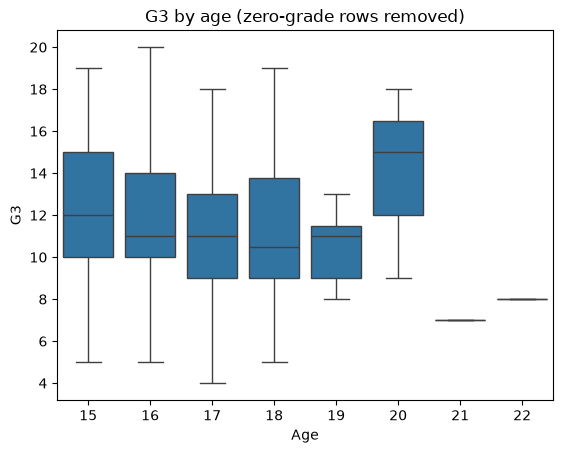

In [23]:
sns.boxplot(x="age", y="G3", data=df_clean)
plt.title("G3 by age (zero-grade rows removed)")
plt.xlabel("Age")
plt.show()

In [24]:
df_clean.groupby("age")["G3"].agg(["mean", "count"]).round(2)

,mean,count
age,,
15,12.14,76
16,11.82,97
17,11.19,90
18,11.19,70
19,10.37,19
20,14.00,3
21,7.00,1
22,8.00,1


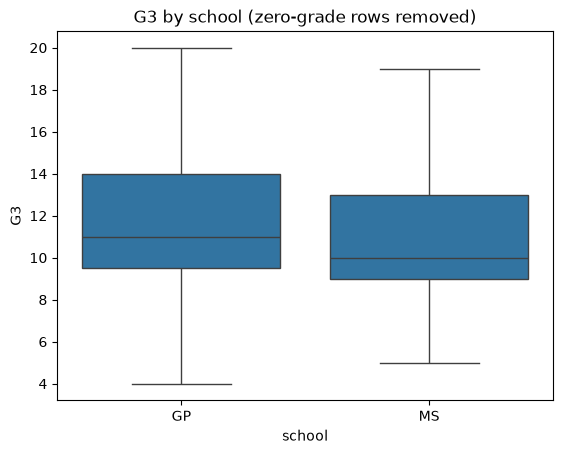

         mean  count
school              
GP      11.62    315
MS      10.79     42



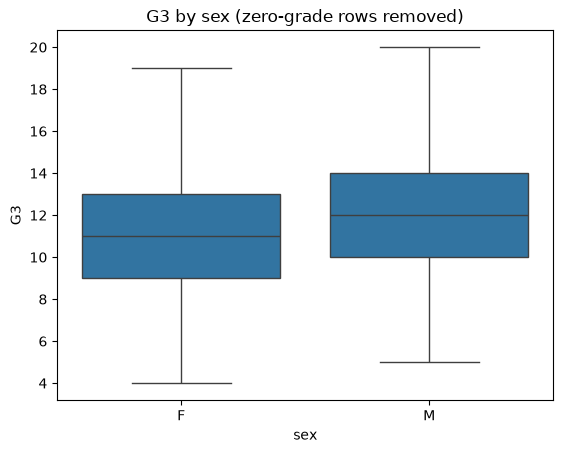

      mean  count
sex              
F    11.21    185
M    11.87    172



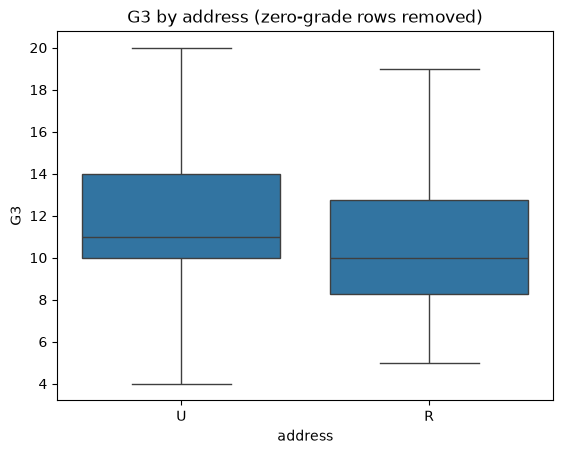

          mean  count
address              
R        10.73     78
U        11.75    279



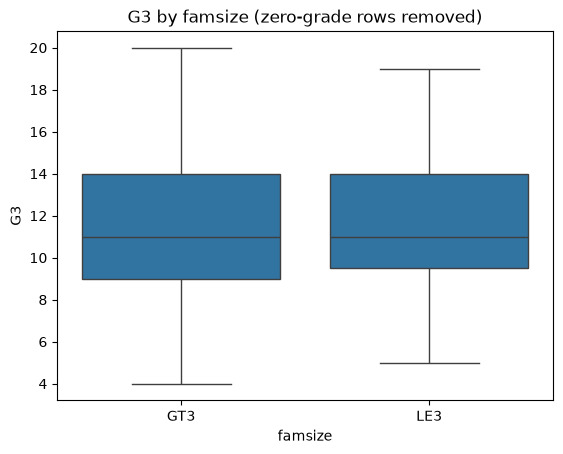

          mean  count
famsize              
GT3      11.44    250
LE3      11.72    107



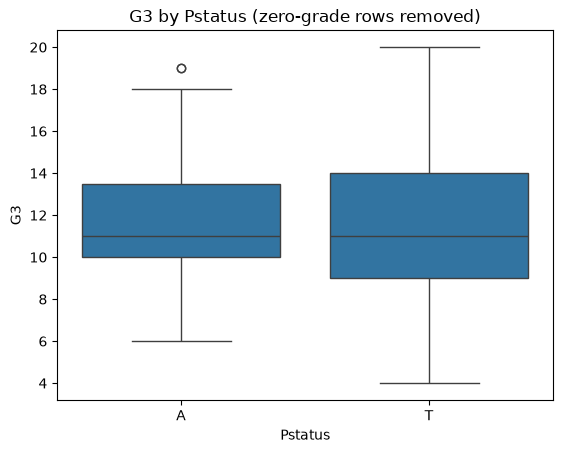

          mean  count
Pstatus              
A        11.77     39
T        11.49    318



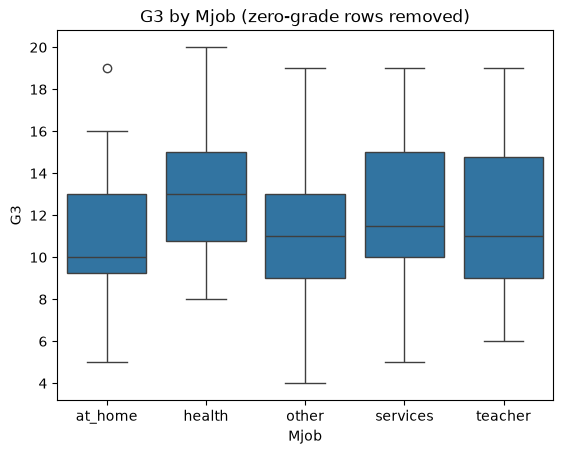

           mean  count
Mjob                  
at_home   10.80     50
health    12.91     32
other     10.91    127
services  12.07     94
teacher   11.87     54



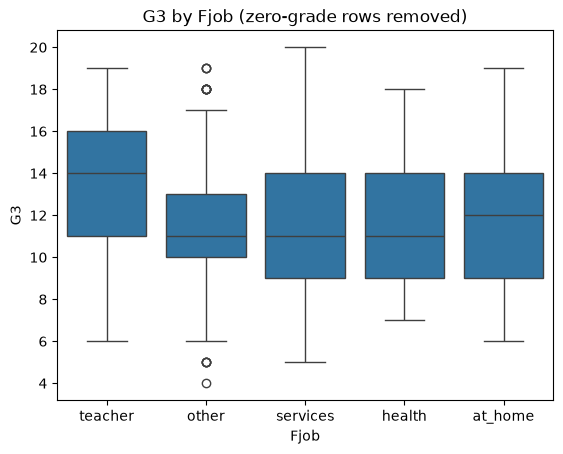

           mean  count
Fjob                  
at_home   11.94     17
health    11.61     18
other     11.29    196
services  11.43    100
teacher   13.35     26



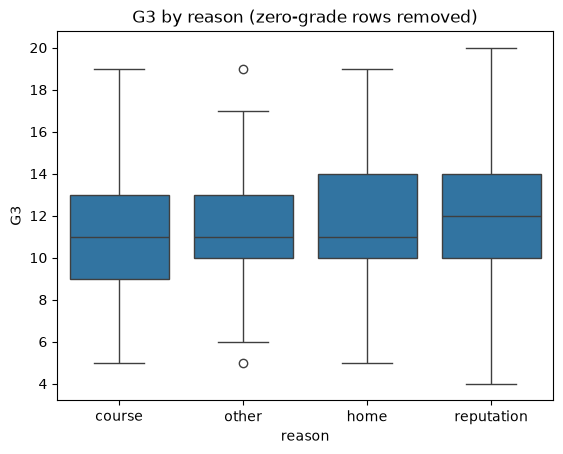

             mean  count
reason                  
course      11.30    126
home        11.53     97
other       11.49     35
reputation  11.82     99



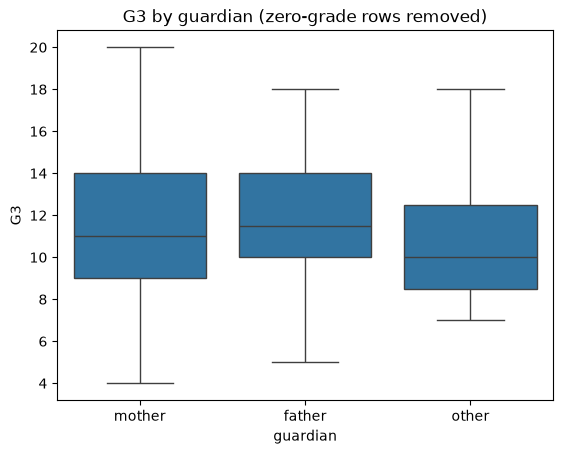

           mean  count
guardian              
father    11.73     82
mother    11.54    248
other     10.74     27



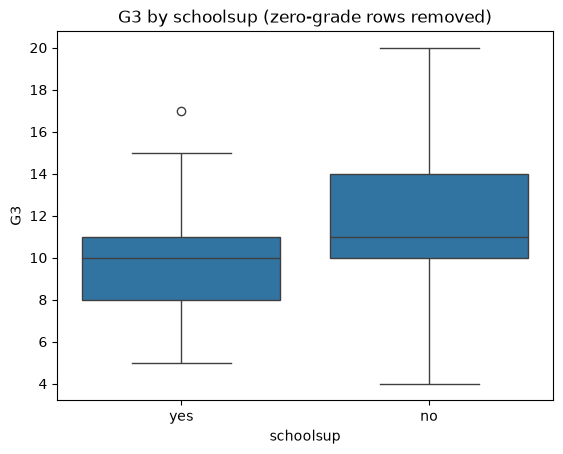

            mean  count
schoolsup              
no         11.83    307
yes         9.62     50



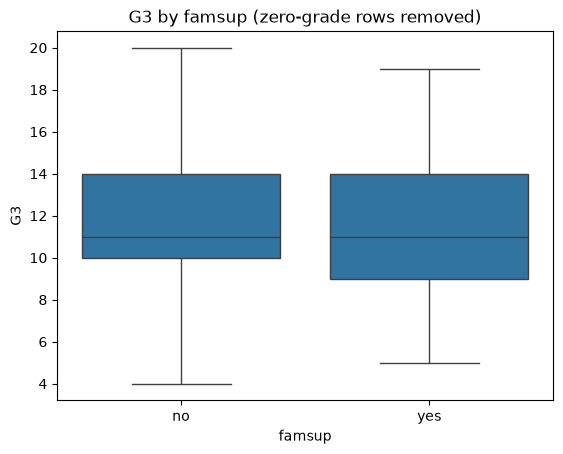

         mean  count
famsup              
no      11.80    138
yes     11.35    219



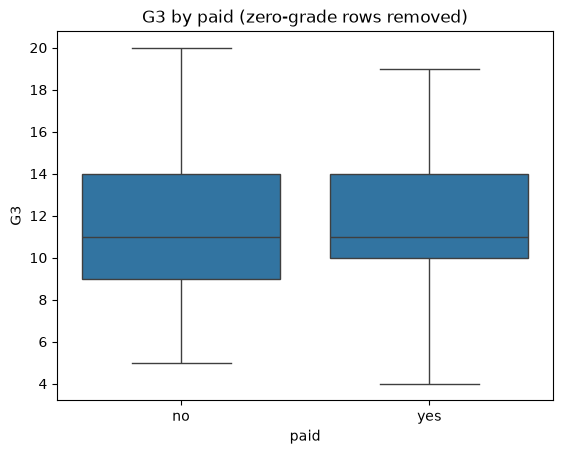

       mean  count
paid              
no    11.61    184
yes   11.43    173



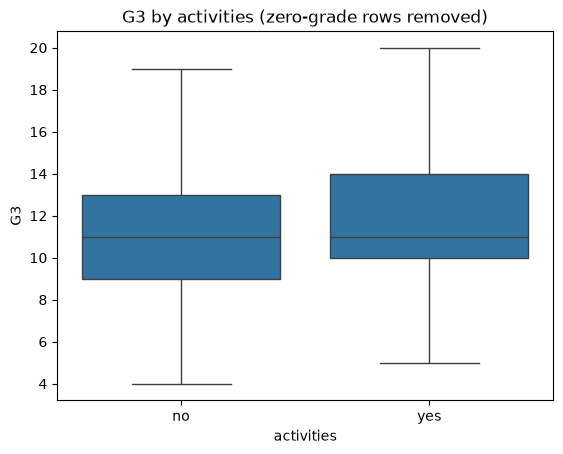

             mean  count
activities              
no          11.33    177
yes         11.71    180



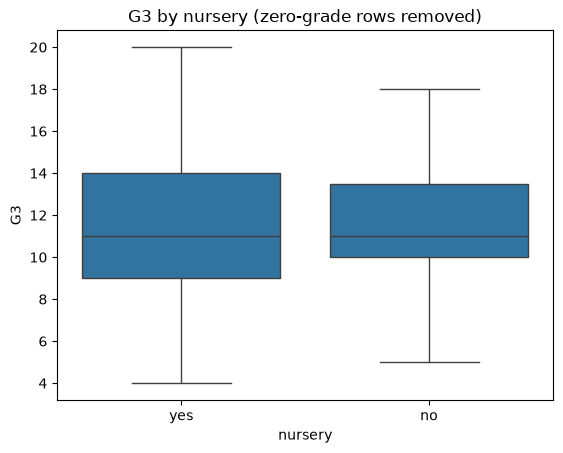

          mean  count
nursery              
no       11.35     71
yes      11.57    286



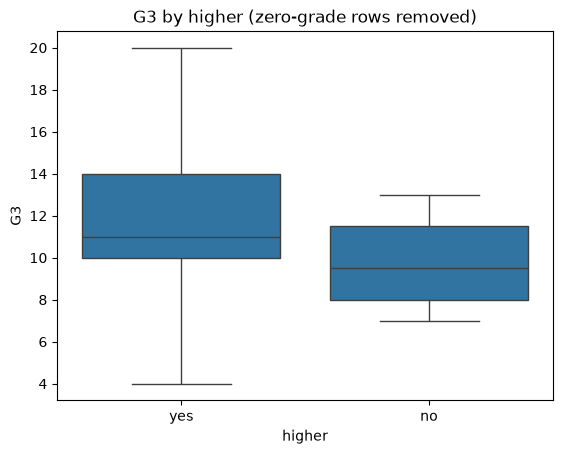

         mean  count
higher              
no       9.71     14
yes     11.60    343



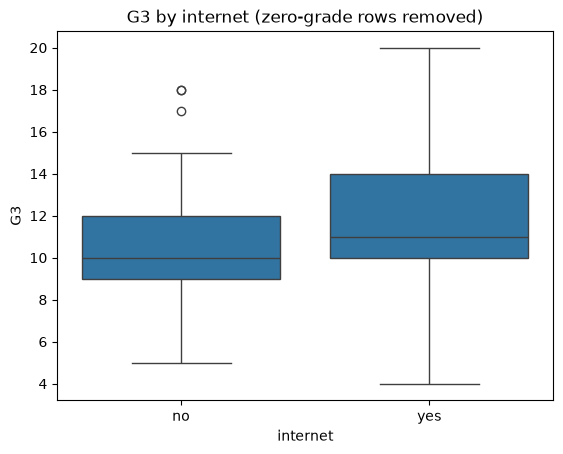

           mean  count
internet              
no        10.71     58
yes       11.68    299



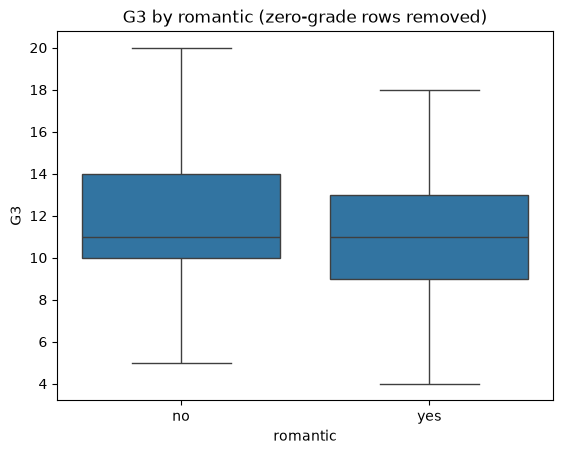

           mean  count
romantic              
no        11.63    245
yes       11.29    112



In [25]:
for col in cat_cols:
    sns.boxplot(x=col, y="G3", data=df_clean)
    plt.title(f"G3 by {col} (zero-grade rows removed)")
    plt.show()
    print(df_clean.groupby(col)["G3"].agg(["mean", "count"]).round(2))
    print()